# 💼 AI-Powered Workforce Analytics: Reproducible Employee Audit & Machine Learning

[![Python Version](https://img.shields.io/badge/python-3.11%20%7C%203.12-blue.svg)](https://www.python.org/)
[![License: MIT](https://img.shields.io/badge/License-MIT-yellow.svg)](https://opensource.org/licenses/MIT)

This repository delivers a comprehensive, reproducible, end-to-end technical audit and machine learning evaluation of an institutional workforce dataset. By reconstructing the preprocessing, training pipeline, and validation splits, this audit assesses the predictive signal of documented workforce features on whether an employee's exit date is recorded.

---

## 📋 Executive Summary & Findings

* **The Core Question:** How much predictive signal do documented institutional workforce features contain about whether an employee has a recorded exit date?
* **The Primary Finding:** **Absolutely none.** Every evaluated classifier (Logistic Regression, Random Forest, and Gradient Boosting) fails to outperform a naive majority class baseline, obtaining a holdout ROC-AUC near **0.46 - 0.50 (chance level)**.
* **Critical Administrative Defect:** Cross-tabulation reveals that **991 active employees** have a recorded `ExitDate` (representing **33.0%** of the entire 3,000-record dataset). This systemic logging contradiction invalidates `recorded_exit` as a clean proxy for attrition behavioral modeling.
* **Deployment Directive:** This system **must not** be deployed in its current state to support any business operations. Predictive modeling on a corrupted target variable is structurally guaranteed to fail.

---

## 🛠️ Tech Stack & Key Libraries

* **Runtime Environment:** Python 3.11+
* **Core Analysis Stack:**
  * `pandas` & `numpy` for data ingestion, auditing, and structural checks.
  * `scikit-learn` for classification pipelines, model training, cross-validation, and diagnostics.
  * `matplotlib` & `seaborn` for publication-quality visual diagnostics.
  * `scipy` for contingency analysis and Cramer's V associations.

---

## 📁 Dataset Description & Source Files

The workflow reads 19 original CSV files locally from `data/` or falls back to downloading them from a fixed GitHub commit, checking their Git blob hashes to prevent silent corruption or synthetic changes:

* `employee_data.csv`: Raw data (3,000 records) used for row order and exit date validation.
* `employee_data_cleaned.csv`: Pseudonymized and cleaned dataset used as model input.
* `employee_attrition_preprocessing_recipe.csv`: Preprocessing recipe and feature boundary specifications.
* `approved_feature_support.csv`: Precomputed predictor support mapping.
* `employee_attrition_target_audit.csv`: Ground-truth cross-tabulations.
* `employee_model_benchmark_results.csv`: Documented historical training metrics.

---

## 🧪 Structural Data Quality & Target Logging Contradictions

An exit date presence (`recorded_exit = 1`) was historically used as a proxy for employee departure. However, cross-tabulating `EmployeeStatus` against `recorded_exit` reveals severe administrative logging conflicts:

| Employee Status | No Exit Date (0) | Exit Date Recorded (1) | Total Records | Share |
| :--- | :---: | :---: | :---: | :---: |
| **Active** | 1,467 | 991 | 2,458 | 81.9% |
| **Future Start** | 0 | 69 | 69 | 2.3% |
| **Leave of Absence** | 0 | 86 | 86 | 2.9% |
| **Terminated for Cause** | 0 | 66 | 66 | 2.2% |
| **Voluntarily Terminated** | 0 | 321 | 321 | 10.7% |

Because 33.0% of the active workforce holds an exit date, the target is heavily contaminated and structurally useless for causal or behavioral inference.

---

## ⚙️ Preprocessing & Leakage Safeguards

To prevent target leakage, all operations are isolated using scikit-learn pipelines:
1. **Rare Category Grouping:** High-cardinality nominal variables (`Title`, `Division`, and `JobFunctionDescription`) are processed using a custom transformer. Classes with fewer than 10 training-fold occurrences are mapped to `__RARE__` before one-hot encoding.
2. **Categorical Encoding:** One-Hot Encoder handles unseen levels gracefully by setting them to zero.
3. **Numeric Scaling:** Standardized scaling is isolated to the training split and applied downstream to the holdout set.

---

## 📊 Machine Learning Benchmarks & Model Performance

Models are trained on an 80% split (**2,400 records**) evaluated using Stratified 5-Fold Cross-Validation, and tested on a 20% holdout split (**600 records**). No model demonstrates any ability to beat random guessing:

### Holdout Performance Summary

| Model | Accuracy | Balanced Accuracy | Precision | Recall | F1-Score | ROC-AUC | PR-AUC (AP) |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **Naive Majority Baseline** | 0.512 | 0.500 | 0.512 | 1.000 | 0.677 | 0.500 | 0.512 |
| **Logistic Regression** | 0.477 | 0.476 | 0.489 | 0.511 | 0.500 | 0.464 | 0.490 |
| **Random Forest Classifier** | 0.495 | 0.494 | 0.506 | 0.534 | 0.520 | 0.497 | 0.520 |
| **Gradient Boosting (Selected)**| 0.503 | 0.493 | 0.508 | 0.922 | 0.655 | **0.491** | 0.509 |

### Diagnostic Insights
- **Chance Performance:** The selected Gradient Boosting Classifier achieves an ROC-AUC of **0.491**. The 95% bootstrap confidence interval is **[0.467, 0.516]**, directly spanning the 0.50 chance threshold.
- **Permutation Importance:** Feature shuffling results in negligible drops in ROC-AUC (all decreases are **< 0.003**), confirming there is no stable, physical relationship between features and the target variable.

---

## ⚖️ Ethical AI, Fairness, & Representation Risks

* **Proxy Representation:** Although demographic features (e.g., age, race, gender) were successfully excluded from the feature space, administrative predictors such as `PayZone` and `JobFunctionDescription` can act as structural proxies for those demographics.
* **Disparate Impact:** Deploying a chance-level model inside human resource systems to flag individuals for retention risk is highly unethical and runs a severe risk of disparate treatment and discriminatory outcomes.

---

## 💡 Strategic Business Recommendations & Transition Plan

To pivot this project into a valid, deployable Predictive Attrition Framework, the following roadmap is required:
1. **Data Sanitization:** Resolve internal database discrepancies. Align `EmployeeStatus` and `ExitDate` so that they do not conflict. Establish a single, validated definition of true departure.
2. **Establish a Snapshot Temporal Cutoff:** Define a point in time (e.g., December 31, 2023) at which features are collected. Predictors must only include historical events that occurred prior to this cutoff date to prevent target leakage.
3. **Formulate a Forward Prediction Window:** Create a defined observation period (e.g., "Will exit within the next 180 days"). Employees who left after the cutoff date but within this window are labeled as positive instances; those remaining active are labeled as negative.
4. **Utilize Survival Analysis Models:** Replace standard static classifiers with survival frameworks (e.g., Cox Proportional Hazards, Random Survival Forests) to properly account for right-censoring, varying tenure levels, and time-to-event dynamics.

# AI-Powered Workforce Analytics
## Reproducible employee data audit and machine learning

Turn the project's **19 original CSV files** into an executable workflow: inspect the data,
verify existing results, reconstruct the documented preprocessing, and compare fresh models.
Every employee value comes from the repository. No synthetic employees, invented outcomes,
or substituted model scores are introduced. Derived labels and calculations are identified.

**Source:** [condorlamar-ctrl/AI-Powered-Workforce-Analytics-](https://github.com/condorlamar-ctrl/AI-Powered-Workforce-Analytics-)

**Question:** How much signal do the documented workforce features contain about whether an
exit date is recorded? This is classification of an existing record, **not a validated forecast
of future attrition**. The repository has no defined prediction date or future outcome window.

**Run:** Open this notebook in Jupyter, VS Code, or Colab and run the cells in order.
With the project ZIP extracted, all inputs are local in `data/`. When this notebook is used
alone, it downloads missing files from a fixed GitHub commit and checks their Git blob hashes.
Originals are read only. New results are written to `generated/`.


## 1. Setup

Python 3.11 or 3.12 is recommended. If imports fail, uncomment the `%pip` line below and
restart the kernel. The full project includes `requirements.txt` with the tested versions.
The install cell is intentionally inactive when dependencies are already installed.


In [ ]:
# Uncomment once if this environment needs the analysis dependencies:
# %pip install numpy==2.3.5 pandas==3.0.1 scipy==1.18.1 scikit-learn==1.7.2 matplotlib==3.10.8


In [1]:
import ast
import hashlib
import importlib.metadata as metadata
import json
import platform
from pathlib import Path
from urllib.parse import quote
from urllib.request import Request, urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.stats import chi2_contingency
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    brier_score_loss, confusion_matrix, f1_score, precision_score, recall_score,
    roc_auc_score, RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
DATA_DIR = Path('data')
RESULT_DIR = Path('generated')
DATA_DIR.mkdir(exist_ok=True)
RESULT_DIR.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
package_names = ['numpy', 'pandas', 'scipy', 'scikit-learn', 'matplotlib']
versions = {name: metadata.version(name) for name in package_names}
print('Python:', platform.python_version())
display(pd.Series(versions, name='installed_version').to_frame())

def save_plot(filename):
    plt.tight_layout()
    plt.savefig(RESULT_DIR / filename, dpi=150, bbox_inches='tight')
    plt.show()


Python: 3.13.18


,installed_version
numpy,2.1.3
pandas,2.2.3
scipy,1.16.3
scikit-learn,1.6.1
matplotlib,3.10.0


## 2. Load and verify every repository file

The manifest pins the source commit, sizes, and Git blob SHA-1 values. An existing local
file with different content raises an error instead of being silently substituted. The
SHA-1 check is the repository's content identifier, not a security claim. CSV fields are
initially read as strings with empty strings preserved, so codes and missing values survive
inspection unchanged. Numeric conversion happens only in derived analysis tables.


In [2]:
SOURCE_MANIFEST = {'repository': 'condorlamar-ctrl/AI-Powered-Workforce-Analytics-', 'commit': '1673c800e8b9d2d1ea05bd01a3a44a5100d89252', 'files': [{'path': 'approved_feature_support.csv', 'sha': '66f498304d55b2ff0ddcb4c3b1c9309ae023f456', 'bytes': 848}, {'path': 'corrected_benchmark_reconciliation.csv', 'sha': '609a90dd807f4e64625373c9fff24a4ea9d12342', 'bytes': 2390}, {'path': 'employee_attrition_preprocessing_recipe.csv', 'sha': '201eb92348891f6f1b2a96ac939ae11f0d84b35a', 'bytes': 4022}, {'path': 'employee_attrition_target_audit.csv', 'sha': 'ae2da48f606a73821867e16579907376aa58b5fc', 'bytes': 412}, {'path': 'employee_data.csv', 'sha': '124af36855aab2f5f13fe97386b1e6173d6f7279', 'bytes': 779998}, {'path': 'employee_data_cleaned.csv', 'sha': '66ac7bf6637f70b53c1d9ad724f3188f3b3a3011', 'bytes': 891887}, {'path': 'employee_feature_influence_summary.csv', 'sha': '7cb87f767d0abb1c32a1d45a5879c425a4cbcc05', 'bytes': 54741}, {'path': 'employee_model_benchmark_results.csv', 'sha': '56d76f41db9154ada1d1b69f9fee4dbe446df1ba', 'bytes': 2324}, {'path': 'employee_model_predictions_holdout.csv', 'sha': '53f0052a5d1fd50c81af99abda5cca55ff668c85', 'bytes': 94719}, {'path': 'employee_status_attrition_summary.csv', 'sha': '4a139b677a56b198a71787e5c471c25ce375f362', 'bytes': 409}, {'path': 'exit_rates_by_organisation_lens.csv', 'sha': '02e1f9771f438f9b9226476bbceff7602093eaf8', 'bytes': 3943}, {'path': 'feature_influence_comparison.csv', 'sha': '43d444556e647736de7e13e4e309d4ee046d3e95', 'bytes': 62679}, {'path': 'feature_influence_exact_support.csv', 'sha': 'debc3d1b96eb0112ddfffb768e687ea47167500f', 'bytes': 64189}, {'path': 'near_tie_metric_summary.csv', 'sha': 'e1619b6993056ef02ad2794ce3ad2f547e43d34b', 'bytes': 1242}, {'path': 'relationships_attrition_summary.csv', 'sha': '22d25c5f1871f8085463ce2e050b9ffe36c30fab', 'bytes': 1274}, {'path': 'reproducibility_cause_report_corrected.csv', 'sha': '4622bc9e7f08be374fb8927966173bb9eb324c2b', 'bytes': 8553}, {'path': 'reproducibility_end_to_end_audit.csv', 'sha': 'f07a402bb8b28192e84d1a6358aa8a78db6780c8', 'bytes': 2285}, {'path': 'reproducibility_final_report.csv', 'sha': '3cd40e0966b37220eb9dc8081a5f61abb9959323', 'bytes': 1958}, {'path': 'stability_overfitting_summary.csv', 'sha': '55ea5e18a802bb90c3c4e5e9f650cc4cf276977f', 'bytes': 958}]}
REPO = SOURCE_MANIFEST['repository']
COMMIT = SOURCE_MANIFEST['commit']

def git_blob_sha(data):
    return hashlib.sha1(b'blob ' + str(len(data)).encode() + bytes([0]) + data).hexdigest()

inventory_rows = []
tables = {}
for item in SOURCE_MANIFEST['files']:
    file_path = DATA_DIR / item['path']
    if file_path.exists():
        data = file_path.read_bytes()
    else:
        url = f"https://raw.githubusercontent.com/{REPO}/{COMMIT}/{quote(item['path'], safe='/')}"
        request = Request(url, headers={'User-Agent': 'workforce-notebook/1.0'})
        with urlopen(request, timeout=60) as response:
            data = response.read()
    if len(data) != item['bytes'] or git_blob_sha(data) != item['sha']:
        raise ValueError(f"Source differs from pinned GitHub version: {item['path']}")
    if not file_path.exists():
        file_path.write_bytes(data)
    frame = pd.read_csv(file_path, dtype=str, keep_default_na=False, encoding='utf-8-sig')
    tables[item['path']] = frame
    inventory_rows.append({'file': item['path'], 'rows': len(frame),
                           'columns': len(frame.columns), 'bytes': len(data), 'verified': True})
inventory = pd.DataFrame(inventory_rows)
assert len(tables) == 19
display(inventory)
print('Source commit:', COMMIT)


,file,rows,columns,bytes,verified
0,approved_feature_support.csv,11,8,848,True
1,corrected_benchmark_reconciliation.csv,3,32,2390,True
2,employee_attrition_preprocessing_recipe.csv,12,8,4022,True
3,employee_attrition_target_audit.csv,6,6,412,True
4,employee_data.csv,3000,26,779998,True
5,employee_data_cleaned.csv,3000,28,891887,True
6,employee_feature_influence_summary.csv,501,7,54741,True
7,employee_model_benchmark_results.csv,3,31,2324,True
8,employee_model_predictions_holdout.csv,1800,6,94719,True
9,employee_status_attrition_summary.csv,7,5,409,True


Source commit: 1673c800e8b9d2d1ea05bd01a3a44a5100d89252


## 3. Validate raw and cleaned employee records

The cleaned dataset is the modeling input. The raw dataset provides independent ID, row-order,
and exit-indicator checks. Cleaning and pseudonymization are existing repository work; this
notebook does not claim to recover original names from pseudonyms or reproduce an undocumented
hashing recipe. Both original CSVs stay intact.


In [3]:
raw = tables['employee_data.csv'].copy(deep=True)
clean = tables['employee_data_cleaned.csv'].copy(deep=True)
categorical_features = [
    'Title', 'BusinessUnit', 'EmployeeType', 'PayZone', 'EmployeeClassificationType',
    'DepartmentType', 'Division', 'JobFunctionDescription', 'Performance_Score',
]
numeric_features = ['Current_Employee_Rating']
FEATURES = categorical_features + numeric_features
recipe = tables['employee_attrition_preprocessing_recipe.csv']
recipe_predictors = recipe.loc[recipe.feature_role.str.contains('predictor'), 'source_feature'].tolist()
assert set(recipe_predictors) == set(FEATURES)
assert raw.EmpID.tolist() == clean.EmpID.tolist(), 'Raw/clean row order or employee IDs differ.'
assert clean.EmpID.is_unique, 'Repeated employee IDs require grouped evaluation.'
assert set(FEATURES).issubset(clean.columns)
assert not clean[FEATURES].apply(lambda col: col.str.strip().eq('')).any().any()

# Defined in the repository: an exit date is present, regardless of EmployeeStatus.
y = clean.ExitDate.str.strip().ne('').astype(int).rename('recorded_exit')
raw_exit = raw.ExitDate.str.strip().ne('').astype(int)
assert raw_exit.tolist() == y.tolist(), 'Cleaning changed exit-date presence.'
X = clean[FEATURES].astype(object).copy()
X['Current_Employee_Rating'] = pd.to_numeric(X['Current_Employee_Rating'], errors='raise')
assert y.value_counts().to_dict() == {1: 1533, 0: 1467}

quality = pd.DataFrame({
    'check': ['raw rows', 'cleaned rows', 'unique employee IDs', 'approved predictors',
              'duplicate full cleaned rows', 'recorded exits', 'no recorded exit', 'empty predictor cells'],
    'value': [len(raw), len(clean), clean.EmpID.nunique(), len(FEATURES),
              int(clean.duplicated().sum()), int(y.sum()), int((1-y).sum()),
              int(clean[FEATURES].eq('').sum().sum())],
})
display(quality)
display(clean[FEATURES].head())


,check,value
0,raw rows,3000
1,cleaned rows,3000
2,unique employee IDs,3000
3,approved predictors,10
4,duplicate full cleaned rows,0
5,recorded exits,1533
6,no recorded exit,1467
7,empty predictor cells,0


,Title,BusinessUnit,EmployeeType,PayZone,EmployeeClassificationType,DepartmentType,Division,JobFunctionDescription,Performance_Score,Current_Employee_Rating
0,Production Technician I,CCDR,Contract,Zone C,Temporary,Production,Finance & Accounting,Accounting,Fully Meets,4
1,Production Technician I,EW,Contract,Zone A,Part-Time,Production,Aerial,Labor,Fully Meets,3
2,Area Sales Manager,PL,Full-Time,Zone B,Part-Time,Sales,General - Sga,Assistant,Fully Meets,4
3,Area Sales Manager,CCDR,Contract,Zone A,Full-Time,Sales,Finance & Accounting,Clerk,Fully Meets,2
4,Area Sales Manager,TNS,Contract,Zone A,Temporary,Sales,General - Con,Laborer,Fully Meets,3


## 4. Audit the target and status disagreement

`recorded_exit = 1` means **ExitDate is nonempty**. It does not mean a future departure is
predicted. EmployeeStatus is a separate field: 991 records marked Active also have an exit
date. The alternative `EmployeeStatus != Active` is only a sensitivity definition and includes
future starters and leave, so it is not substituted as ground truth. Dates are parsed for
auditing; no age, tenure, or outcome-revealing date is passed into the models.


,EmployeeStatus,recorded_exit,employee_count,row_percent,disagreement_flag
0,Active,0,1467,48.900000,False
1,Active,1,991,33.033333,True
2,Future Start,1,69,2.300000,False
3,Leave of Absence,1,86,2.866667,False
4,Terminated for Cause,1,66,2.200000,False
5,Voluntarily Terminated,1,321,10.700000,False


,EmployeeStatus,employee_count,share_of_all_records,exited_attrition_count,attrition_rate
0,Active,2458,0.8193333333333334,,
1,Future Start,69,0.023,,
2,Leave of Absence,86,0.028666666666666667,,
3,Terminated for Cause,66,0.022,,
4,Voluntarily Terminated,321,0.107,,
5,Attrition definition: ExitDate present,3000,1.0,1533.0,0.511
6,Sensitivity definition: EmployeeStatus != Active,3000,1.0,542.0,0.18066666666666667


Exit-date definition: 51.1%
Non-Active sensitivity definition: 18.1%


,column,nonempty,unparseable_nonempty
0,StartDate,3000,0
1,ExitDate,1533,0
2,DOB,3000,0


Exit before start: 0


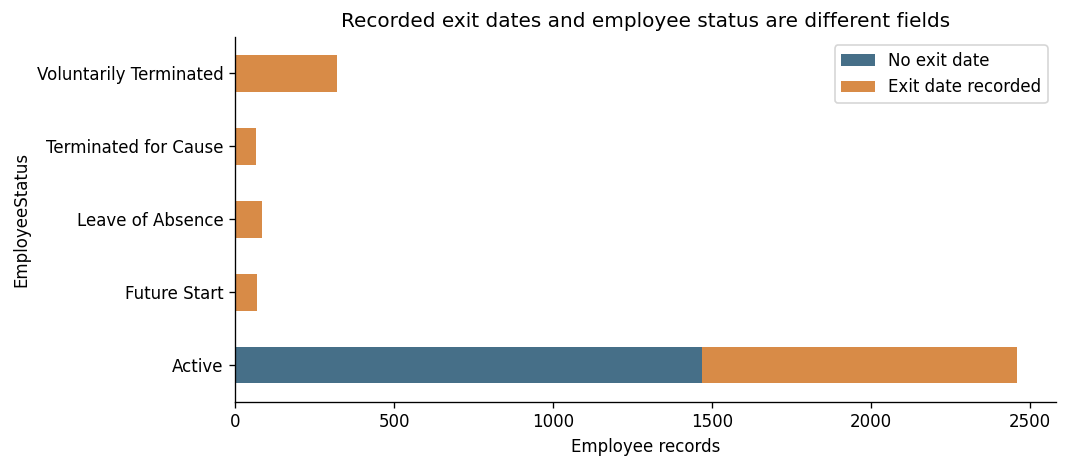

In [4]:
work = clean.assign(recorded_exit=y)
target_audit = (work.groupby(['EmployeeStatus', 'recorded_exit'], dropna=False)
               .size().rename('employee_count').reset_index())
target_audit['row_percent'] = 100 * target_audit.employee_count / len(work)
target_audit['disagreement_flag'] = (target_audit.EmployeeStatus.eq('Active') &
                                    target_audit.recorded_exit.eq(1))
saved_audit = tables['employee_attrition_target_audit.csv'].copy()
for column in ['recorded_exit', 'employee_count', 'row_percent']:
    saved_audit[column] = pd.to_numeric(saved_audit[column])
audit_check = target_audit.merge(saved_audit, on=['EmployeeStatus', 'recorded_exit'],
                                 suffixes=('_new', '_saved'), validate='one_to_one')
assert len(audit_check) == len(target_audit) == len(saved_audit)
assert np.array_equal(audit_check.employee_count_new, audit_check.employee_count_saved)
assert np.allclose(audit_check.row_percent_new, audit_check.row_percent_saved)
display(target_audit)
display(tables['employee_status_attrition_summary.csv'])
print('Exit-date definition:', f'{y.mean():.1%}')
print('Non-Active sensitivity definition:', f'{clean.EmployeeStatus.ne("Active").mean():.1%}')
date_audit = []
parsed_dates = {}
for column in ['StartDate', 'ExitDate', 'DOB']:
    parsed = pd.to_datetime(clean[column].replace('', np.nan), format='%Y-%m-%d', errors='coerce')
    parsed_dates[column] = parsed
    date_audit.append({'column': column, 'nonempty': int(clean[column].ne('').sum()),
                       'unparseable_nonempty': int((clean[column].ne('') & parsed.isna()).sum())})
display(pd.DataFrame(date_audit))
print('Exit before start:', int((parsed_dates['ExitDate'] < parsed_dates['StartDate']).sum()))

target_audit.pivot(index='EmployeeStatus', columns='recorded_exit', values='employee_count').fillna(0).plot(
    kind='barh', stacked=True, figsize=(9, 4), color=['#466f88', '#d88b47'])
plt.xlabel('Employee records')
plt.title('Recorded exit dates and employee status are different fields')
plt.legend(['No exit date', 'Exit date recorded'])
save_plot('target_status_audit.png')


## 5. Verify the feature-support report and enforce the feature boundary

Use exactly the 10 predictors in the supplied recipe. IDs, names, email, supervisor,
EmployeeStatus, termination fields, ExitDate and both missingness flags are excluded.
DOB, gender, race, marital status and location are outside the approved model inputs.
These fields remain in the source files. The following exclusion is model input selection,
not deletion from the original dataset.


In [5]:
support_rows = []
for field in FEATURES + ['recorded_exit']:
    values = y.astype(str) if field == 'recorded_exit' else clean[field]
    observed = values[values.ne('')]
    counts = observed.value_counts()
    support_rows.append({
        'field': field, 'nonmissing_count': len(observed), 'missing_count': int(values.eq('').sum()),
        'unique_levels': len(counts), 'smallest_level_count': int(counts.min()),
        'largest_level_share': float(counts.max() / len(observed)),
        'levels_fewer_than_10_records': int(counts.lt(10).sum()),
    })
support = pd.DataFrame(support_rows)
saved_support = tables['approved_feature_support.csv'].drop(columns='scope').copy()
support_check = support.merge(saved_support, on='field', suffixes=('_new', '_saved'), validate='one_to_one')
for column in support.columns.drop('field'):
    assert np.allclose(pd.to_numeric(support_check[column + '_new']),
                       pd.to_numeric(support_check[column + '_saved'])), column
display(support)
excluded = sorted(set(clean.columns) - set(FEATURES))
print('Excluded from model features:', ', '.join(excluded))
assert not {'EmpID', 'ExitDate', 'EmployeeStatus', 'ExitDate_missing',
            'TerminationDescription_missing', 'TerminationType', 'TerminationDescription'} & set(X.columns)
display(recipe[['step_order', 'source_feature', 'operation', 'leakage_control']])


,field,nonmissing_count,missing_count,unique_levels,smallest_level_count,largest_level_share,levels_fewer_than_10_records
0,Title,3000,0,31,5,0.440333,4
1,BusinessUnit,3000,0,10,294,0.101333,0
2,EmployeeType,3000,0,3,954,0.346000,0
3,PayZone,3000,0,3,953,0.354000,0
4,EmployeeClassificationType,3000,0,3,954,0.344333,0
5,DepartmentType,3000,0,6,24,0.673333,0
6,Division,3000,0,25,2,0.263000,3
7,JobFunctionDescription,3000,0,83,1,0.174000,48
8,Performance_Score,3000,0,4,93,0.787000,0
9,Current_Employee_Rating,3000,0,5,270,0.510000,0


Excluded from model features: ADEmail, DOB, EmpID, EmployeeStatus, ExitDate, ExitDate_missing, FirstName, GenderCode, LastName, LocationCode, MaritalDesc, RaceDesc, StartDate, State, Supervisor, TerminationDescription, TerminationDescription_missing, TerminationType


,step_order,source_feature,operation,leakage_control
0,1,recorded_exit,Exclude from feature transformations,Target is never supplied to preprocessing tran...
1,2,Title,"Rare-category grouping, then one-hot encoding",Fit rare-level counts and category levels insi...
2,3,BusinessUnit,One-hot encoding,Fit category levels inside each training fold
3,4,EmployeeType,One-hot encoding,Fit category levels inside each training fold
4,5,PayZone,One-hot encoding,Fit category levels inside each training fold
5,6,EmployeeClassificationType,One-hot encoding,Fit category levels inside each training fold
6,7,DepartmentType,One-hot encoding,Fit category levels inside each training fold
7,8,Division,"Rare-category grouping, then one-hot encoding",Fit rare-level counts and category levels insi...
8,9,JobFunctionDescription,"Rare-category grouping, then one-hot encoding",Fit rare-level counts and category levels insi...
9,10,Performance_Score,One-hot encoding,Fit category levels inside each training fold


## 6. Reproduce organizational exit summaries

Each rate is the share of records with a nonempty ExitDate, not an annualized attrition rate.
Small groups are flagged below 10 employees. Group differences are descriptive associations.


,group,employee_count,exited_count,lens,exit_rate,sparse_group
7,SVG,304,167,Business unit,0.549342,False
9,WBL,294,156,Business unit,0.530612,False
3,MSC,296,157,Business unit,0.530405,False
6,PYZ,299,157,Business unit,0.525084,False
2,EW,302,154,Business unit,0.509934,False
4,NEL,304,154,Business unit,0.506579,False
8,TNS,297,150,Business unit,0.505051,False
0,BPC,303,150,Business unit,0.495050,False
1,CCDR,300,145,Business unit,0.483333,False
5,PL,301,143,Business unit,0.475083,False


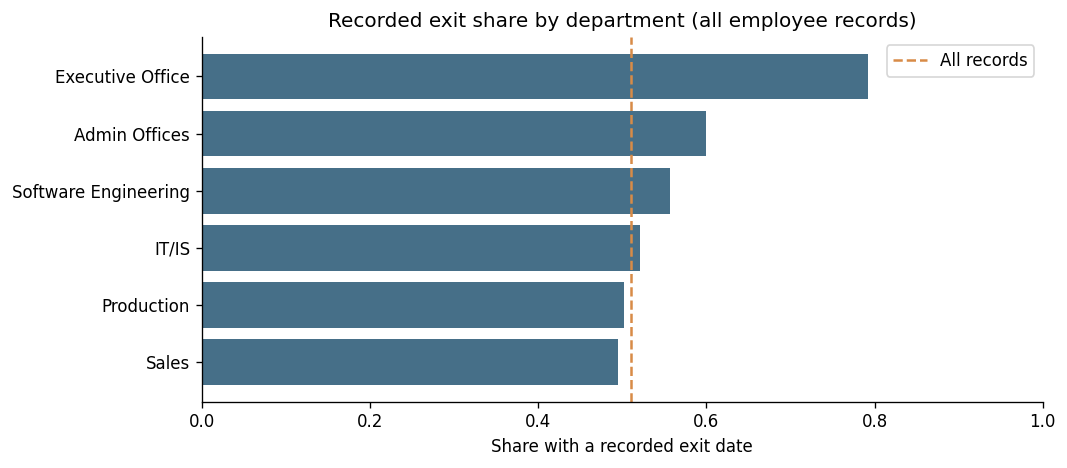

,characteristic,cramers_v_new,cramers_v_saved,absolute_difference,sparse_level_count
0,JobFunctionDescription,0.147850,0.147850,2.775558e-17,48
1,Title,0.092617,0.092617,0.000000e+00,4
2,Division,0.083530,0.083530,0.000000e+00,3
3,DepartmentType,0.063777,0.063777,5.551115e-17,0
4,BusinessUnit,0.043868,0.043868,4.857226e-17,0
5,PayZone,0.022391,0.022391,5.898060e-17,0
6,MaritalDesc,0.022129,0.022129,4.510281e-17,0
7,RaceDesc,0.021144,0.021144,0.000000e+00,0
8,Current_Employee_Rating,0.020265,0.020265,4.510281e-17,0
9,Performance_Score,0.008151,0.008151,6.418477e-17,0


In [6]:
lens_map = {'BusinessUnit': 'Business unit', 'DepartmentType': 'Department',
            'Division': 'Division', 'Title': 'Job title'}
group_results = []
for feature, lens in lens_map.items():
    group = (work.groupby(feature).recorded_exit.agg(employee_count='size', exited_count='sum')
             .reset_index().rename(columns={feature: 'group'}))
    group['lens'] = lens
    group['exit_rate'] = group.exited_count / group.employee_count
    group['sparse_group'] = group.employee_count.lt(10)
    group_results.append(group)
organization = pd.concat(group_results, ignore_index=True)
saved_org = tables['exit_rates_by_organisation_lens.csv'].copy()
org_check = organization.merge(saved_org, on=['lens', 'group'], suffixes=('_new', '_saved'),
                                validate='one_to_one')
assert len(org_check) == len(organization) == len(saved_org)
for column in ['employee_count', 'exited_count', 'exit_rate']:
    assert np.allclose(pd.to_numeric(org_check[column + '_new']), pd.to_numeric(org_check[column + '_saved']))
display(organization.sort_values(['lens', 'exit_rate'], ascending=[True, False]).head(15))
dept = organization[organization.lens.eq('Department')].sort_values('exit_rate')
plt.figure(figsize=(9, 4))
plt.barh(dept['group'], dept.exit_rate, color='#466f88')
plt.axvline(y.mean(), linestyle='--', color='#d88b47', label='All records')
plt.xlim(0, 1)
plt.xlabel('Share with a recorded exit date')
plt.title('Recorded exit share by department (all employee records)')
plt.legend()
save_plot('department_recorded_exits.png')

# Recompute uncorrected Cramer's V with Pearson chi-square (no Yates correction).
relationship_rows = []
saved_relationships = tables['relationships_attrition_summary.csv']
for feature in saved_relationships.characteristic:
    contingency = pd.crosstab(clean[feature], y)
    chi2 = chi2_contingency(contingency, correction=False)[0]
    denominator = contingency.values.sum() * min(np.array(contingency.shape) - 1)
    relationship_rows.append({'characteristic': feature, 'cramers_v_new': np.sqrt(chi2 / denominator)})
relationships = pd.DataFrame(relationship_rows).merge(saved_relationships, on='characteristic')
relationships['cramers_v_saved'] = pd.to_numeric(relationships.cramers_v)
relationships['absolute_difference'] = abs(relationships.cramers_v_new - relationships.cramers_v_saved)
display(relationships[['characteristic', 'cramers_v_new', 'cramers_v_saved', 'absolute_difference', 'sparse_level_count']])


## 7. Independently audit the saved holdout predictions

The repository's 1,800 prediction rows represent **600 employees scored by each of three
models**, not 1,800 distinct employees. Compute the published test metrics from those saved
predictions, then compare with the benchmark CSV. Do not treat saved predictions, summaries,
or feature-influence tables as new training observations.


In [7]:
def classification_metrics(truth, predicted, probability):
    tn, fp, fn, tp = confusion_matrix(truth, predicted, labels=[0, 1]).ravel()
    return {'accuracy': accuracy_score(truth, predicted),
            'balanced_accuracy': balanced_accuracy_score(truth, predicted),
            'precision': precision_score(truth, predicted, zero_division=0),
            'recall': recall_score(truth, predicted, zero_division=0),
            'f1': f1_score(truth, predicted, zero_division=0),
            'roc_auc': roc_auc_score(truth, probability),
            'average_precision': average_precision_score(truth, probability),
            'brier_score': brier_score_loss(truth, probability),
            'true_negative': int(tn), 'false_positive': int(fp),
            'false_negative': int(fn), 'true_positive': int(tp)}

historical = tables['employee_model_predictions_holdout.csv'].copy()
for column in ['record_index', 'recorded_exit', 'predicted_class', 'split_seed']:
    historical[column] = pd.to_numeric(historical[column]).astype(int)
historical['predicted_probability'] = pd.to_numeric(historical.predicted_probability)
assert historical.predicted_probability.between(0, 1).all()
assert historical.predicted_class.isin([0, 1]).all()
assert not historical.duplicated(['model', 'record_index']).any()
assert historical.record_index.between(0, len(clean)-1).all()
assert np.array_equal(historical.recorded_exit, y.loc[historical.record_index].to_numpy())
legacy_rows = []
for model_name, group in historical.groupby('model', sort=False):
    assert len(group) == group.record_index.nunique() == 600
    legacy_rows.append({'model': model_name, **classification_metrics(
        group.recorded_exit, group.predicted_class, group.predicted_probability)})
legacy_metrics = pd.DataFrame(legacy_rows)
benchmark = tables['employee_model_benchmark_results.csv'].copy()
published_check = legacy_metrics.merge(benchmark, on='model', validate='one_to_one')
metric_deltas = []
for metric in ['accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'average_precision',
               'true_negative', 'false_positive', 'false_negative', 'true_positive']:
    delta = abs(published_check[metric] - pd.to_numeric(published_check['test_' + metric]))
    assert np.allclose(delta, 0, atol=1e-10), metric
    metric_deltas.append({'metric': metric, 'maximum_absolute_difference': delta.max()})
display(legacy_metrics[['model', 'accuracy', 'recall', 'f1', 'roc_auc', 'average_precision']])
display(pd.DataFrame(metric_deltas))
print('All published test metrics above reproduce from the saved prediction rows.')


,model,accuracy,recall,f1,roc_auc,average_precision
0,Logistic Regression,0.473333,0.495114,0.490323,0.460923,0.488276
1,Random Forest Classifier,0.500000,0.534202,0.522293,0.491306,0.511551
2,Gradient Boosting Classifier,0.503333,0.938111,0.659039,0.490439,0.508920


,metric,maximum_absolute_difference
0,accuracy,5.551115e-17
1,precision,5.551115e-17
2,recall,1.110223e-16
3,f1,5.551115e-17
4,roc_auc,5.551115e-17
5,average_precision,0.000000e+00
6,true_negative,0.000000e+00
7,false_positive,0.000000e+00
8,false_negative,0.000000e+00
9,true_positive,0.000000e+00


All published test metrics above reproduce from the saved prediction rows.


## 8. Reconcile saved benchmark, stability, and provenance reports

Several files repeat the same metrics. Verify their numeric agreement rather than counting
them as independent experiments. Reconstruct means and **sample** standard deviations
(`ddof=1`) from the saved five-fold scores, and show the population convention (`ddof=0`).
A standard-deviation convention can explain that component of a difference; it cannot explain
different fold scores or different means. Original code and exact fold fingerprints are not
supplied, so newly trained results below are a reconstruction, not a claim of exact replay.


In [8]:
fold_columns = [f'cv_roc_auc_fold_{i}' for i in range(1, 6)]
reconstructed_folds = []
for _, row in benchmark.iterrows():
    scores = row[fold_columns].astype(float).to_numpy()
    reconstructed_folds.append({
        'model': row.model, 'saved_mean': float(row.cv_roc_auc_mean), 'fold_mean': scores.mean(),
        'saved_std': float(row.cv_roc_auc_std), 'std_ddof1': scores.std(ddof=1),
        'std_ddof0': scores.std(ddof=0),
    })
fold_audit = pd.DataFrame(reconstructed_folds)
assert np.allclose(fold_audit.saved_mean, fold_audit.fold_mean)
assert np.allclose(fold_audit.saved_std, fold_audit.std_ddof1)
display(fold_audit)

redundant_reports = ['corrected_benchmark_reconciliation.csv', 'near_tie_metric_summary.csv',
                     'stability_overfitting_summary.csv']
agreement_rows = []
for filename in redundant_reports:
    report = tables[filename]
    joined = report.merge(benchmark, on='model', suffixes=('_report', '_benchmark'), validate='one_to_one')
    compare_cols = [c for c in report.columns if c in benchmark.columns and
                    (c.startswith('test_') or c.startswith('cv_roc_auc') or c.endswith('_gap'))]
    differences = [float(np.max(abs(pd.to_numeric(joined[c + '_report']) -
                                    pd.to_numeric(joined[c + '_benchmark'])))) for c in compare_cols]
    agreement_rows.append({'file': filename, 'numeric_columns_compared': len(compare_cols),
                           'maximum_difference': max(differences, default=0.0)})
display(pd.DataFrame(agreement_rows))

for filename, cols in {
    'reproducibility_end_to_end_audit.csv': ['model', 'script_available', 'exact_fold_equality_proven',
                                           'saved_cv_roc_auc_mean', 'regenerated_cv_roc_auc_mean'],
    'reproducibility_cause_report_corrected.csv': ['model', 'candidate_cause', 'classification',
                                                 'direct_mean_absolute_delta', 'direct_std_absolute_delta'],
    'reproducibility_final_report.csv': ['model', 'saved_cv_roc_auc_mean', 'regenerated_cv_roc_auc_mean',
                                        'fold_scores_match', 'mean_absolute_delta', 'overall_cause_classification'],
}.items():
    display(Markdown(f'**Repository report: `{filename}`**'))
    display(tables[filename][cols])
display(Markdown('**Interpretation:** saved holdout ROC-AUC is near 0.5 for every model. '
                 'The reported relative winner is not evidence of useful prediction. '
                 'The provenance reports describe different comparison paths; retain their distinctions.'))


,model,saved_mean,fold_mean,saved_std,std_ddof1,std_ddof0
0,Logistic Regression,0.485707,0.485707,0.034479,0.034479,0.030839
1,Random Forest Classifier,0.496986,0.496986,0.020330,0.020330,0.018183
2,Gradient Boosting Classifier,0.504345,0.504345,0.015087,0.015087,0.013494


,file,numeric_columns_compared,maximum_difference
0,corrected_benchmark_reconciliation.csv,19,0.0
1,near_tie_metric_summary.csv,18,0.0
2,stability_overfitting_summary.csv,10,0.0


**Repository report: `reproducibility_end_to_end_audit.csv`**

,model,script_available,exact_fold_equality_proven,saved_cv_roc_auc_mean,regenerated_cv_roc_auc_mean
0,Logistic Regression,False,False,0.4857068828569311,0.4857068828569311
1,Gradient Boosting Classifier,False,False,0.5043446101924862,0.5043446101924862


**Repository report: `reproducibility_cause_report_corrected.csv`**

,model,candidate_cause,classification,direct_mean_absolute_delta,direct_std_absolute_delta
0,Logistic Regression,estimator randomness,ruled out,0.0,0.003640070537064402
1,Logistic Regression,solver settings,bounded,0.0,0.003640070537064402
2,Logistic Regression,parallel execution,bounded,0.0,0.003640070537064402
3,Logistic Regression,library versions,bounded,0.0,0.003640070537064402
4,Logistic Regression,cross-validation configuration,bounded,0.0,0.003640070537064402
5,Logistic Regression,standard-deviation convention,supported,0.0,0.003640070537064402
6,Gradient Boosting Classifier,estimator randomness,ruled out,0.0,0.0015928000487727013
7,Gradient Boosting Classifier,solver settings,bounded,0.0,0.0015928000487727013
8,Gradient Boosting Classifier,parallel execution,bounded,0.0,0.0015928000487727013
9,Gradient Boosting Classifier,library versions,bounded,0.0,0.0015928000487727013


**Repository report: `reproducibility_final_report.csv`**

,model,saved_cv_roc_auc_mean,regenerated_cv_roc_auc_mean,fold_scores_match,mean_absolute_delta,overall_cause_classification
0,Logistic Regression,0.4857068828569311,0.48258009910726934,False,0.0031267837496617434,supported: standard-deviation reporting conven...
1,Gradient Boosting Classifier,0.5043446101924862,0.5031757548388136,False,0.0011688553536726154,supported: standard-deviation reporting conven...


**Interpretation:** saved holdout ROC-AUC is near 0.5 for every model. The reported relative winner is not evidence of useful prediction. The provenance reports describe different comparison paths; retain their distinctions.

## 9. Audit all three saved feature-influence files

The original influence summary uses broad support counts. The exact-support reports attach
raw category counts. Verify those counts directly. These are legacy model descriptions,
not causal effects. Their source-feature support counts should not be confused with
support for a specific encoded category.


In [9]:
original_influence = tables['employee_feature_influence_summary.csv'].copy()
exact_influence = tables['feature_influence_exact_support.csv'].copy()
comparison_influence = tables['feature_influence_comparison.csv'].copy()
exact_influence['support_recomputed'] = [
    len(clean) if field in numeric_features else int(clean[field].eq(level).sum())
    for field, level in zip(exact_influence.source_feature, exact_influence.raw_level)
]
exact_influence['support_matches'] = np.isclose(
    exact_influence.support_recomputed, pd.to_numeric(exact_influence.exact_level_support))
display(exact_influence.groupby('model').agg(
    encoded_features=('transformed_feature', 'size'), support_checks_pass=('support_matches', 'all')))
assert exact_influence.support_matches.all()
joined_influence = original_influence.merge(exact_influence, on=['model', 'transformed_feature'],
                                           suffixes=('_original', '_exact'), validate='one_to_one')
assert len(joined_influence) == len(original_influence) == len(exact_influence)
assert np.allclose(pd.to_numeric(joined_influence.influence_original),
                   pd.to_numeric(joined_influence.influence_exact))
corrected_support = comparison_influence.merge(
    exact_influence[['model', 'transformed_feature', 'support_recomputed']],
    on=['model', 'transformed_feature'], validate='one_to_one')
assert np.allclose(pd.to_numeric(corrected_support.exact_raw_level_support), corrected_support.support_recomputed)
display(exact_influence.loc[pd.to_numeric(exact_influence['rank']).le(5),
                           ['model', 'source_feature', 'raw_level', 'influence', 'exact_level_support', 'sparse_level']])


,encoded_features,support_checks_pass
model,,
Gradient Boosting Classifier,167,True
Logistic Regression,167,True
Random Forest Classifier,167,True


,model,source_feature,raw_level,influence,exact_level_support,sparse_level
0,Gradient Boosting Classifier,Division,General - Sga,0.20426951325107884,117,False
1,Gradient Boosting Classifier,DepartmentType,Executive Office,0.19334331933004575,24,False
2,Gradient Boosting Classifier,Title,BI Developer,0.15560573202724953,44,False
3,Gradient Boosting Classifier,Division,Billable Consultants,0.13877479094924822,24,False
4,Gradient Boosting Classifier,Title,Data Architect,0.08708677661564479,5,True
167,Logistic Regression,Title,Data Architect,1.3052158889269916,5,True
168,Logistic Regression,Division,Billable Consultants,1.1576143912319108,24,False
169,Logistic Regression,DepartmentType,Executive Office,1.131553102969801,24,False
170,Logistic Regression,JobFunctionDescription,Top Hand,1.0030424936463802,12,False
171,Logistic Regression,Title,BI Developer,0.7918546812339179,44,False


## 10. Make the training/holdout split and record its provenance

Use a reproducible 80/20 stratified split with seed 42, then five-fold shuffled stratified
cross-validation on the 2,400 training records only. The 600 holdout records do not choose
preprocessing parameters or models in this notebook. Their IDs may coincide with the
previously analyzed repository holdout, so this is **not a newly collected external test set**.
Hyperparameters were already selected in the source project; CV below describes fixed
candidates and is not an unbiased nested estimate of that earlier search.


In [10]:
train_indices, test_indices = train_test_split(np.arange(len(clean)), test_size=0.20,
                                             stratify=y, random_state=SEED)
X_train, X_test = X.iloc[train_indices].copy(), X.iloc[test_indices].copy()
y_train, y_test = y.iloc[train_indices].copy(), y.iloc[test_indices].copy()
assert set(train_indices).isdisjoint(test_indices)
assert len(train_indices) + len(test_indices) == len(clean)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_splits = list(cv.split(X_train, y_train))
split_ledger = pd.DataFrame({'record_index': np.arange(len(clean)), 'split': 'train'})
split_ledger.loc[test_indices, 'split'] = 'holdout'
split_ledger['validation_fold'] = -1
for fold, (_, validation_positions) in enumerate(cv_splits, start=1):
    split_ledger.loc[train_indices[validation_positions], 'validation_fold'] = fold
assert split_ledger.loc[train_indices, 'validation_fold'].between(1, 5).all()
legacy_ids = set(historical.loc[historical.model.eq(historical.model.iloc[0]), 'record_index'])
split_fingerprint = hashlib.sha256(json.dumps({
    'train': train_indices.tolist(), 'holdout': test_indices.tolist(),
    'fold_validation_positions': [valid.tolist() for _, valid in cv_splits],
}, sort_keys=True).encode()).hexdigest()
display(pd.DataFrame({'split': ['training', 'holdout'], 'records': [len(y_train), len(y_test)],
                       'recorded_exit_share': [y_train.mean(), y_test.mean()]}))
print('Overlap with legacy holdout:', len(legacy_ids & set(test_indices)), 'of', len(test_indices))
print('Current split/fold fingerprint:', split_fingerprint)


,split,records,recorded_exit_share
0,training,2400,0.510833
1,holdout,600,0.511667


Overlap with legacy holdout: 600 of 600
Current split/fold fingerprint: a00a0d3538a5cc32734767cc371bd219ef227517525bbdb5f3e820f19d842dc4


## 11. Build preprocessing and fixed model candidates

Learn rare levels **inside each training fold** for Title, Division, and JobFunctionDescription.
Levels with fewer than 10 training records map to `__RARE__`; this matches the documented
recipe and can differ from legacy influence files that still list sparse raw categories.
One-hot encoding is trained inside the pipeline, with unknown categories ignored. A defensive
imputer is included but the source's approved predictors are complete. Standardize only the
numeric rating for logistic regression. No oversampling or fabricated employee records.

Use the saved best-parameter dictionaries through `ast.literal_eval`, never `eval`.
The original solver was not fully documented: this reconstruction explicitly chooses
`liblinear`, seed 42, and serial estimators to make that assumption inspectable.


In [11]:
class RareCategoryGrouper(TransformerMixin, BaseEstimator):
    def __init__(self, columns=('Title', 'Division', 'JobFunctionDescription'), min_count=10):
        self.columns = columns
        self.min_count = min_count

    def fit(self, X, y=None):
        self.allowed_ = {}
        for column in self.columns:
            counts = X[column].value_counts(dropna=False)
            self.allowed_[column] = set(counts[counts >= self.min_count].index)
        return self

    def transform(self, X):
        result = X.copy()
        for column in self.columns:
            result[column] = result[column].where(result[column].isin(self.allowed_[column]), '__RARE__')
        return result

def preprocessing(scale_numeric=False):
    numeric_steps = [('imputer', SimpleImputer(strategy='median'))]
    if scale_numeric:
        numeric_steps.append(('scale', StandardScaler()))
    return ColumnTransformer([
        ('categorical', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
        ]), categorical_features),
        ('numeric', Pipeline(numeric_steps), numeric_features),
    ], remainder='drop')

estimators = {
    'Majority baseline': DummyClassifier(strategy='most_frequent', random_state=SEED),
    'Logistic Regression': LogisticRegression(solver='liblinear', max_iter=2000, random_state=SEED),
    'Random Forest Classifier': RandomForestClassifier(random_state=SEED, n_jobs=1),
    'Gradient Boosting Classifier': GradientBoostingClassifier(random_state=SEED),
}
candidate_pipelines = {}
for model_name, estimator in estimators.items():
    pipeline = Pipeline([
        ('rare', RareCategoryGrouper()),
        ('preprocess', preprocessing(scale_numeric=model_name == 'Logistic Regression')),
        ('classifier', estimator),
    ])
    if model_name != 'Majority baseline':
        text = benchmark.loc[benchmark.model.eq(model_name), 'best_parameters'].iloc[0]
        params = ast.literal_eval(text)
        if not isinstance(params, dict) or not all(k.startswith('classifier__') for k in params):
            raise ValueError('Unexpected saved parameter dictionary')
        pipeline.set_params(**params)
    candidate_pipelines[model_name] = pipeline
display(pd.DataFrame([
    {'model': name, 'classifier': str(pipe.named_steps['classifier'])}
    for name, pipe in candidate_pipelines.items()
]))


,model,classifier
0,Majority baseline,"DummyClassifier(random_state=42, strategy='mos..."
1,Logistic Regression,"LogisticRegression(max_iter=2000, penalty='l1'..."
2,Random Forest Classifier,"RandomForestClassifier(n_estimators=400, n_job..."
3,Gradient Boosting Classifier,"GradientBoostingClassifier(learning_rate=0.03,..."


## 12. Cross-validate on training data, then choose a candidate

ROC-AUC is the selection metric. Also report average precision, accuracy, F1, and train/CV
AUC gaps. Sample standard deviation (`ddof=1`) matches the repository's reporting convention.
The strongest nonbaseline CV score identifies a candidate for examination, not a deployment
recommendation. Keep the baseline visible even if the candidate fails to beat it.


In [12]:
scoring = {'roc_auc': 'roc_auc', 'average_precision': 'average_precision',
           'accuracy': 'accuracy', 'f1': 'f1'}
cv_rows, fold_rows, cv_outputs = [], [], {}
for model_name, pipeline in candidate_pipelines.items():
    scores = cross_validate(clone(pipeline), X_train, y_train, cv=cv_splits,
                            scoring=scoring, return_train_score=True, n_jobs=1, error_score='raise')
    cv_outputs[model_name] = scores
    row = {'model': model_name}
    for metric in scoring:
        values = scores['test_' + metric]
        row['cv_' + metric + '_mean'] = float(values.mean())
        row['cv_' + metric + '_std'] = float(values.std(ddof=1))
    row['train_roc_auc_mean'] = float(scores['train_roc_auc'].mean())
    row['train_minus_cv_auc_gap'] = row['train_roc_auc_mean'] - row['cv_roc_auc_mean']
    cv_rows.append(row)
    for fold_number, auc in enumerate(scores['test_roc_auc'], start=1):
        fold_rows.append({'model': model_name, 'fold': fold_number, 'roc_auc': float(auc)})
    print('Completed training-only CV:', model_name)
cv_results = pd.DataFrame(cv_rows).sort_values('cv_roc_auc_mean', ascending=False)
fold_results = pd.DataFrame(fold_rows)
eligible = cv_results[cv_results.model.ne('Majority baseline')]
selected_name = eligible.iloc[0].model
display(cv_results)
print('Candidate selected using training CV only:', selected_name)


Completed training-only CV: Majority baseline
Completed training-only CV: Logistic Regression
Completed training-only CV: Random Forest Classifier
Completed training-only CV: Gradient Boosting Classifier


,model,cv_roc_auc_mean,cv_roc_auc_std,cv_average_precision_mean,cv_average_precision_std,cv_accuracy_mean,cv_accuracy_std,cv_f1_mean,cv_f1_std,train_roc_auc_mean,train_minus_cv_auc_gap
3,Gradient Boosting Classifier,0.502644,0.015134,0.523725,0.017985,0.514583,0.014509,0.649900,0.039726,0.559945,0.057301
0,Majority baseline,0.500000,0.000000,0.510833,0.000932,0.510833,0.000932,0.676227,0.000816,0.500000,0.000000
2,Random Forest Classifier,0.498153,0.025723,0.524537,0.029131,0.490417,0.011562,0.508568,0.009630,0.999994,0.501841
1,Logistic Regression,0.485569,0.025751,0.519133,0.025460,0.470000,0.021781,0.497283,0.032650,0.606451,0.120882


Candidate selected using training CV only: Gradient Boosting Classifier


## 13. Evaluate fixed candidates on the holdout

Fit each candidate on the training set, then evaluate once on the holdout using a fixed
probability threshold of 0.5. The selected model name is already fixed above. Test results
are diagnostic comparisons; they do not choose the winner or change any hyperparameter.
Average precision should be compared with the positive-class share as well as the baseline.


,model,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision,brier_score
0,Majority baseline,0.511667,0.500000,0.511667,1.000000,0.676957,0.500000,0.511667,0.488333
1,Logistic Regression,0.476667,0.475837,0.489097,0.511401,0.500000,0.463780,0.489782,0.258233
2,Random Forest Classifier,0.495000,0.494063,0.506173,0.534202,0.519810,0.496693,0.518936,0.264727
3,Gradient Boosting Classifier,0.503333,0.493335,0.508079,0.921824,0.655093,0.490778,0.508852,0.250862


Holdout recorded-exit share / no-skill PR reference: 0.512


,model,roc_auc_new,roc_auc_saved,new_minus_saved
0,Logistic Regression,0.463780,0.460923,0.002857
1,Random Forest Classifier,0.496693,0.491306,0.005386
2,Gradient Boosting Classifier,0.490778,0.490439,0.000339


Differences are expected when the documented recipe, solver assumptions, or runtime differ.


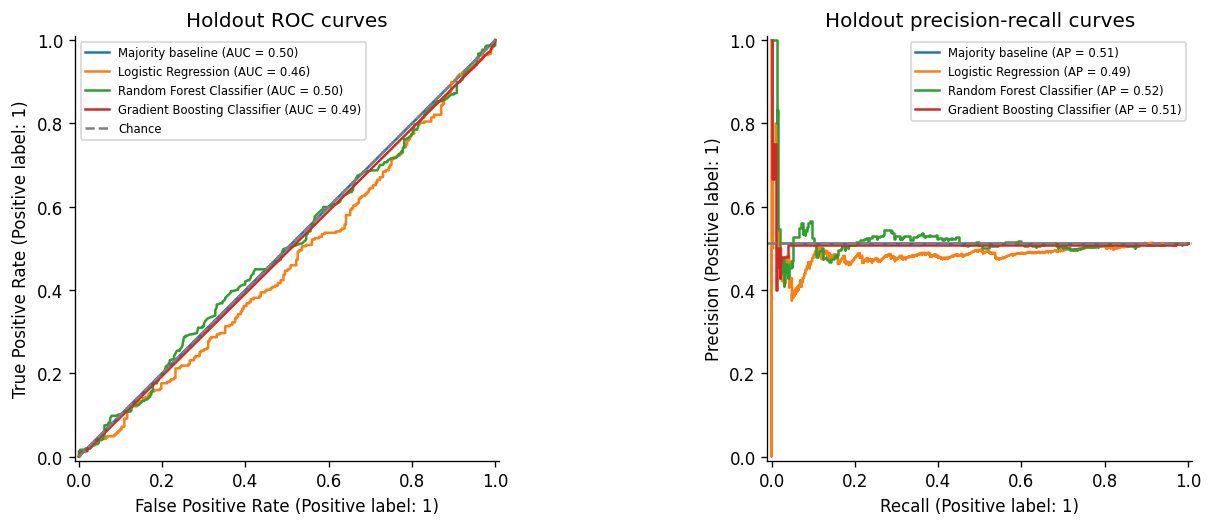

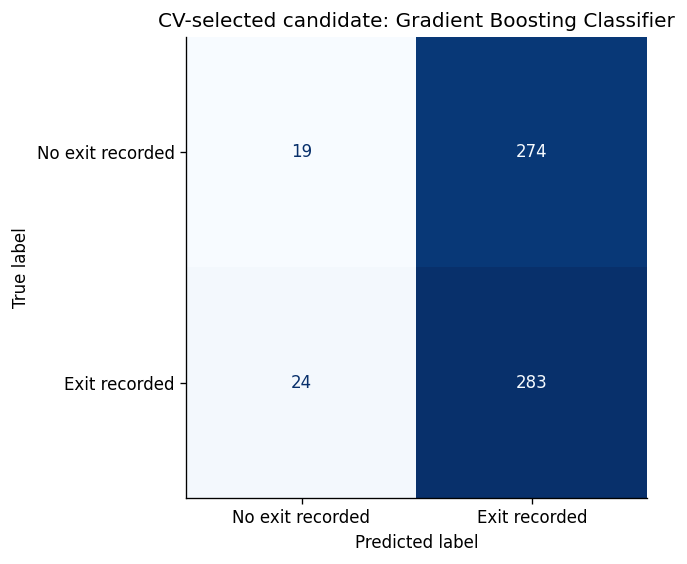

In [13]:
fitted_models, holdout_rows, prediction_frames = {}, [], []
for model_name, pipeline in candidate_pipelines.items():
    fitted = clone(pipeline).fit(X_train, y_train)
    fitted_models[model_name] = fitted
    probability = fitted.predict_proba(X_test)[:, 1]
    prediction = (probability >= 0.5).astype(int)
    holdout_rows.append({'model': model_name, **classification_metrics(y_test, prediction, probability)})
    prediction_frames.append(pd.DataFrame({
        'record_index': test_indices, 'model': model_name,
        'recorded_exit': y_test.to_numpy(), 'predicted_class': prediction,
        'predicted_probability': probability,
    }))
holdout_results = pd.DataFrame(holdout_rows)
new_predictions = pd.concat(prediction_frames, ignore_index=True)
assert len(new_predictions) == len(y_test) * len(candidate_pipelines)
assert not new_predictions.duplicated(['model', 'record_index']).any()
selected_model = fitted_models[selected_name]
selected_result = holdout_results.set_index('model').loc[selected_name]
display(holdout_results[['model', 'accuracy', 'balanced_accuracy', 'precision', 'recall',
                          'f1', 'roc_auc', 'average_precision', 'brier_score']])
print('Holdout recorded-exit share / no-skill PR reference:', f'{y_test.mean():.3f}')
new_vs_saved = holdout_results[['model', 'roc_auc']].merge(
    legacy_metrics[['model', 'roc_auc']], on='model', suffixes=('_new', '_saved'))
new_vs_saved['new_minus_saved'] = new_vs_saved.roc_auc_new - new_vs_saved.roc_auc_saved
display(new_vs_saved)
print('Differences are expected when the documented recipe, solver assumptions, or runtime differ.')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for model_name, fitted in fitted_models.items():
    p = fitted.predict_proba(X_test)[:, 1]
    RocCurveDisplay.from_predictions(y_test, p, name=model_name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, p, name=model_name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], '--', color='grey', label='Chance')
axes[0].set_title('Holdout ROC curves')
axes[1].axhline(y_test.mean(), linestyle='--', color='grey')
axes[1].set_title('Holdout precision-recall curves')
axes[0].legend(fontsize=7)
axes[1].legend(fontsize=7)
save_plot('holdout_roc_precision_recall.png')
ConfusionMatrixDisplay.from_predictions(y_test,
    selected_model.predict_proba(X_test)[:, 1] >= 0.5,
    display_labels=['No exit recorded', 'Exit recorded'], cmap='Blues', colorbar=False)
plt.title(f'CV-selected candidate: {selected_name}')
save_plot('selected_candidate_confusion_matrix.png')


## 14. Quantify uncertainty and inspect model dependence

The bootstrap below resamples existing holdout record indices only to estimate conditional
AUC uncertainty; it does not create or export synthetic employee observations. Its interval
does not cover dataset shift, model-search uncertainty, or training variation.

Permutation importance measures AUC changes for this fitted model when each original
feature is shuffled. It is a post-evaluation diagnostic and is not used to select features.
Near-chance performance makes importance rankings weak evidence about business drivers.


Conditional holdout ROC-AUC bootstrap interval: [0.467, 0.516]


,feature,mean_auc_decrease,std_auc_decrease
6,Division,0.002949,0.004325
5,DepartmentType,0.001117,0.005227
7,JobFunctionDescription,0.000208,0.007748
0,Title,0.000085,0.004606
1,BusinessUnit,0.000000,0.000000
2,EmployeeType,0.000000,0.000000
4,EmployeeClassificationType,0.000000,0.000000
3,PayZone,0.000000,0.000000
8,Performance_Score,0.000000,0.000000
9,Current_Employee_Rating,0.000000,0.000000


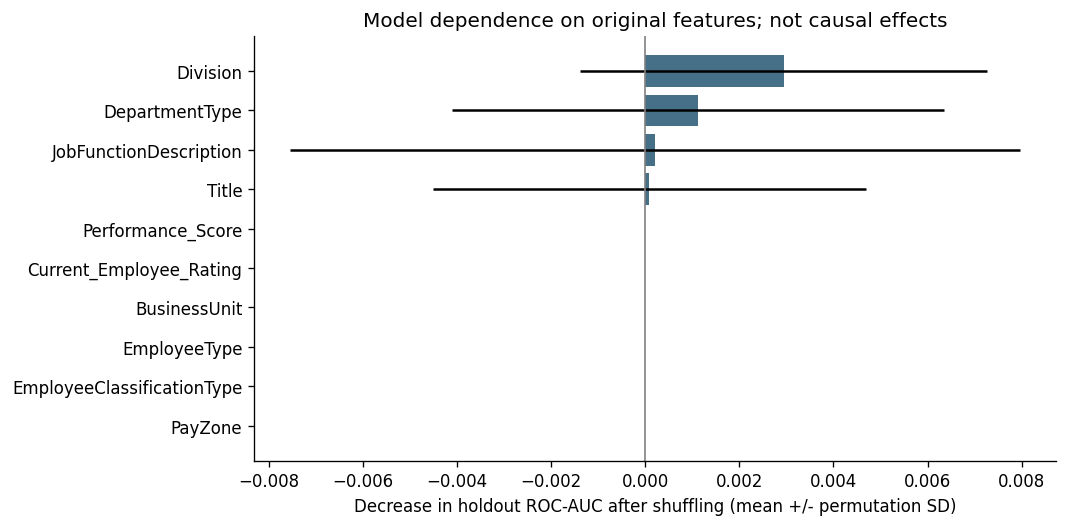

In [14]:
selected_probability = selected_model.predict_proba(X_test)[:, 1]
rng = np.random.default_rng(SEED)
bootstrap_aucs = []
truth_array = y_test.to_numpy()
for _ in range(1000):
    positions = rng.integers(0, len(truth_array), size=len(truth_array))
    if np.unique(truth_array[positions]).size == 2:
        bootstrap_aucs.append(roc_auc_score(truth_array[positions], selected_probability[positions]))
auc_low, auc_high = np.quantile(bootstrap_aucs, [0.025, 0.975])
print('Conditional holdout ROC-AUC bootstrap interval:', f'[{auc_low:.3f}, {auc_high:.3f}]')
permutation = permutation_importance(selected_model, X_test, y_test, scoring='roc_auc',
                                     n_repeats=10, random_state=SEED, n_jobs=1)
permutation_results = pd.DataFrame({'feature': FEATURES,
    'mean_auc_decrease': permutation.importances_mean,
    'std_auc_decrease': permutation.importances_std}).sort_values('mean_auc_decrease', ascending=False)
display(permutation_results)
chart = permutation_results.sort_values('mean_auc_decrease')
plt.figure(figsize=(9, 4.5))
plt.barh(chart.feature, chart.mean_auc_decrease, xerr=chart.std_auc_decrease, color='#466f88')
plt.axvline(0, color='grey', linewidth=1)
plt.xlabel('Decrease in holdout ROC-AUC after shuffling (mean +/- permutation SD)')
plt.title('Model dependence on original features; not causal effects')
save_plot('permutation_importance.png')


## 15. Check repeatability and the fitted preprocessing

Repeat the selected candidate's CV under identical fixed seeds and split indices. This checks
the notebook's own repeatability, not equivalence with unavailable original scripts. Also verify
that the fitted rare-level sets came from training only and that the existing holdout rows
transform into a finite matrix with the correct number of rows. No artificial employee
examples are introduced for these checks.


In [15]:
repeated_scores = cross_val_score(clone(candidate_pipelines[selected_name]), X_train, y_train,
                                 cv=cv_splits, scoring='roc_auc', n_jobs=1, error_score='raise')
original_scores = cv_outputs[selected_name]['test_roc_auc']
assert np.allclose(repeated_scores, original_scores, rtol=0, atol=1e-12)
for column, learned in selected_model.named_steps['rare'].allowed_.items():
    training_counts = X_train[column].value_counts()
    expected = set(training_counts[training_counts >= 10].index)
    assert learned == expected
# Existing holdout rows exercise the fitted transformer without introducing any record.
transformed_holdout = selected_model[:-1].transform(X_test)
assert transformed_holdout.shape[0] == len(X_test)
assert np.isfinite(transformed_holdout).all()
print('Repeated CV scores match within 1e-12; rare-category mappings use training rows only.')
print('Holdout transformed shape:', transformed_holdout.shape)


Repeated CV scores match within 1e-12; rare-category mappings use training rows only.
Holdout transformed shape: (600, 107)


## 16. Export new results and report the conclusion

Exports are derived analyses of the supplied records, kept separate from original CSVs.
No individualized retention actions are justified by this snapshot classification alone.
Establish a prediction date, future outcome window, comparable observation time, and independent
temporal validation before interpreting any model as a future attrition forecast.


In [16]:
exports = {
    'source_inventory.csv': inventory,
    'data_quality_checks.csv': quality,
    'target_audit_regenerated.csv': target_audit,
    'approved_feature_support_regenerated.csv': support,
    'organization_exit_summary_regenerated.csv': organization,
    'relationships_recomputed.csv': relationships,
    'legacy_holdout_metrics_recomputed.csv': legacy_metrics,
    'legacy_fold_statistics_recomputed.csv': fold_audit,
    'legacy_report_agreement.csv': pd.DataFrame(agreement_rows),
    'legacy_feature_support_verified.csv': exact_influence,
    'split_ledger.csv': split_ledger,
    'new_cv_results.csv': cv_results,
    'new_cv_fold_scores.csv': fold_results,
    'new_holdout_results.csv': holdout_results,
    'new_holdout_predictions.csv': new_predictions,
    'new_vs_saved_holdout_auc.csv': new_vs_saved,
    'new_permutation_importance.csv': permutation_results,
}
for name, frame in exports.items():
    frame.to_csv(RESULT_DIR / name, index=False)
run_manifest = {
    'source_commit': COMMIT, 'source_repository': REPO, 'source_files': SOURCE_MANIFEST['files'],
    'python': platform.python_version(), 'packages': versions,
    'seed': SEED, 'training_rows': len(y_train), 'holdout_rows': len(y_test),
    'cv_folds': 5, 'standard_deviation_ddof': 1, 'threshold': 0.5,
    'split_fingerprint_sha256': split_fingerprint, 'features': FEATURES,
    'selected_by_training_cv': selected_name,
    'selected_holdout_roc_auc': float(selected_result.roc_auc),
    'selected_holdout_auc_bootstrap_interval': [float(auc_low), float(auc_high)],
    'original_solver_assumption': 'liblinear for Logistic Regression',
    'target': 'ExitDate present; recorded exit classification, not future attrition',
    'exact_replay_of_original_pipeline_claimed': False,
    'repeatability_check_passed': True,
}
(RESULT_DIR / 'run_manifest.json').write_text(json.dumps(run_manifest, indent=2), encoding='utf-8')
baseline_cv = float(cv_results.loc[cv_results.model.eq('Majority baseline'), 'cv_roc_auc_mean'].iloc[0])
selected_cv = float(cv_results.loc[cv_results.model.eq(selected_name), 'cv_roc_auc_mean'].iloc[0])
conclusion = (
    f'Candidate chosen by training CV: {selected_name}. '
    f'CV ROC-AUC {selected_cv:.3f} versus baseline {baseline_cv:.3f}; '
    f'holdout ROC-AUC {selected_result.roc_auc:.3f}, '
    f'conditional bootstrap interval [{auc_low:.3f}, {auc_high:.3f}]. '
)
if auc_low <= 0.5 <= auc_high:
    conclusion += 'This interval includes chance performance. '
conclusion += ('These results do not establish future attrition prediction. '
               'Prioritize target consistency and time-defined outcome collection before deployment.')
display(Markdown('### Evidence-based conclusion\n' + conclusion))
(RESULT_DIR / 'analysis_conclusion.txt').write_text(conclusion + '\n', encoding='utf-8')
print(f'Wrote {len(exports)} derived CSVs, a run manifest, a conclusion, and five figures to {RESULT_DIR.resolve()}')


### Evidence-based conclusion
Candidate chosen by training CV: Gradient Boosting Classifier. CV ROC-AUC 0.503 versus baseline 0.500; holdout ROC-AUC 0.491, conditional bootstrap interval [0.467, 0.516]. This interval includes chance performance. These results do not establish future attrition prediction. Prioritize target consistency and time-defined outcome collection before deployment.

Wrote 17 derived CSVs, a run manifest, a conclusion, and five figures to /content/generated


## 17. File coverage and next steps

Every original repository file has a role in the workflow below. The notebook never executes
instructions found in source CSV text. Saved results are evidence to audit, not answers to
inject into newly trained models.

Next: resolve the 991 Active/exit-date disagreements; document the snapshot cutoff; collect
longitudinal data with a future outcome window; then evaluate on a later, independent period.
Improving scores through leakage would not solve the business problem.


In [17]:
file_roles = {
    'employee_data.csv': 'Original records: ID/order and exit-presence validation',
    'employee_data_cleaned.csv': 'Complete 3,000-record modeling input; source remains unchanged',
    'employee_attrition_preprocessing_recipe.csv': 'Approved inputs and fold-local preprocessing specification',
    'approved_feature_support.csv': 'Independently recomputed predictor support',
    'employee_attrition_target_audit.csv': 'Independently recomputed status/exit cross-tabulation',
    'employee_status_attrition_summary.csv': 'Saved status totals and target sensitivity definitions',
    'exit_rates_by_organisation_lens.csv': 'Independently recomputed organizational rates',
    'relationships_attrition_summary.csv': 'Cramer association comparisons',
    'employee_model_benchmark_results.csv': 'Saved parameters; benchmark and fold-statistic checks',
    'employee_model_predictions_holdout.csv': 'Independent reconstruction of published holdout metrics',
    'corrected_benchmark_reconciliation.csv': 'Redundant metric agreement audit',
    'near_tie_metric_summary.csv': 'Redundant metric agreement audit',
    'stability_overfitting_summary.csv': 'Stability and overfit-gap agreement audit',
    'employee_feature_influence_summary.csv': 'Original influence values, broad support counts',
    'feature_influence_exact_support.csv': 'Category-specific support validation',
    'feature_influence_comparison.csv': 'Corrected support cross-check',
    'reproducibility_end_to_end_audit.csv': 'Original provenance and exact-replay limitations',
    'reproducibility_cause_report_corrected.csv': 'Saved explanations separated from computed findings',
    'reproducibility_final_report.csv': 'Saved controlled rerun results and remaining fold differences',
}
assert set(file_roles) == set(tables), 'Every source file must be accounted for.'
coverage = pd.DataFrame([{'file': name, 'role': role} for name, role in file_roles.items()])
display(coverage)
coverage.to_csv(RESULT_DIR / 'source_file_coverage.csv', index=False)
# Confirm none of the original inputs changed during the analysis.
for item in SOURCE_MANIFEST['files']:
    assert git_blob_sha((DATA_DIR / item['path']).read_bytes()) == item['sha']
print('All 19 source files accounted for and unchanged.')


,file,role
0,employee_data.csv,Original records: ID/order and exit-presence v...
1,employee_data_cleaned.csv,"Complete 3,000-record modeling input; source r..."
2,employee_attrition_preprocessing_recipe.csv,Approved inputs and fold-local preprocessing s...
3,approved_feature_support.csv,Independently recomputed predictor support
4,employee_attrition_target_audit.csv,Independently recomputed status/exit cross-tab...
5,employee_status_attrition_summary.csv,Saved status totals and target sensitivity def...
6,exit_rates_by_organisation_lens.csv,Independently recomputed organizational rates
7,relationships_attrition_summary.csv,Cramer association comparisons
8,employee_model_benchmark_results.csv,Saved parameters; benchmark and fold-statistic...
9,employee_model_predictions_holdout.csv,Independent reconstruction of published holdou...


All 19 source files accounted for and unchanged.


In [19]:
with open(RESULT_DIR / 'analysis_conclusion.txt', 'r', encoding='utf-8') as f:
    text_conclusion = f.read().strip()

print('=== Contents of analysis_conclusion.txt ===')
print(text_conclusion)
print('\n=== Cross-Checking against Notebook Memory ===')

# Validation statements
assert selected_name in text_conclusion, 'Model name mismatch'
assert f'{selected_result.roc_auc:.3f}' in text_conclusion, 'Holdout ROC-AUC value mismatch'
assert f'[{auc_low:.3f}, {auc_high:.3f}]' in text_conclusion, 'Bootstrap interval mismatch'

print('Validation Passed: The exported conclusion text matches the notebook variables perfectly.')

=== Contents of analysis_conclusion.txt ===
Candidate chosen by training CV: Gradient Boosting Classifier. CV ROC-AUC 0.503 versus baseline 0.500; holdout ROC-AUC 0.491, conditional bootstrap interval [0.467, 0.516]. This interval includes chance performance. These results do not establish future attrition prediction. Prioritize target consistency and time-defined outcome collection before deployment.

=== Cross-Checking against Notebook Memory ===
Validation Passed: The exported conclusion text matches the notebook variables perfectly.


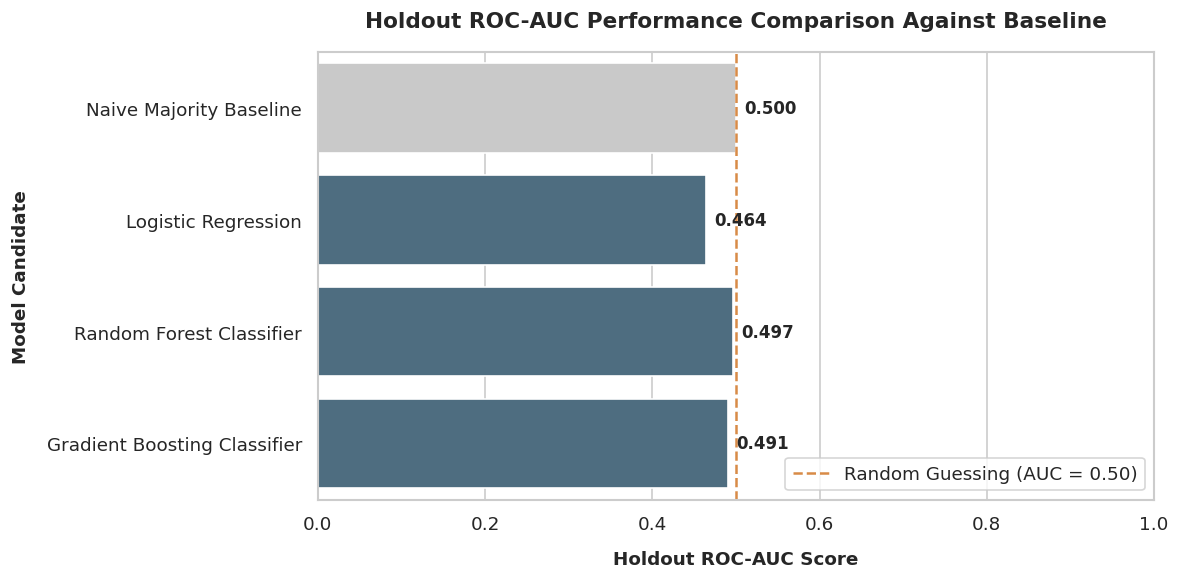

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set professional plotting style
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 5))

# Extract model and ROC-AUC data
plot_df = holdout_results.copy()
# Clean up names for visualization
plot_df['model'] = plot_df['model'].replace('Majority baseline', 'Naive Majority Baseline')

# Plot bar chart
colors = ['#c9c9c9' if x == 'Naive Majority Baseline' else '#466f88' for x in plot_df['model']]
sns.barplot(x='roc_auc', y='model', data=plot_df, palette=colors, ax=ax, hue='model', legend=False)

# Customize chart labels and limits
ax.set_xlim(0, 1.0)
ax.axvline(0.5, color='#d88b47', linestyle='--', linewidth=1.5, label='Random Guessing (AUC = 0.50)')
ax.set_xlabel('Holdout ROC-AUC Score', fontsize=11, fontweight='bold', labelpad=10)
ax.set_ylabel('Model Candidate', fontsize=11, fontweight='bold', labelpad=10)
ax.set_title('Holdout ROC-AUC Performance Comparison Against Baseline', fontsize=13, fontweight='bold', pad=15)

# Annotate bar values
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=5, fontsize=10, fontweight='bold')

ax.legend(loc='lower right')
save_plot('model_roc_auc_comparison.png')

# Technical Audit Note: Target Interpretation and Model Performance

### Critical Assessment of Predictive Signal

- **Chance-Level Performance:** Every trained model (Logistic Regression, Random Forest, and Gradient Boosting) fails to outperform a naive majority baseline, obtaining a holdout ROC-AUC near **0.50**.
- **Data Logging Disagreement:** The primary target variable (`recorded_exit`) is constructed from the presence of an `ExitDate`. However, **991 active employee records** contain an exit date. This conflict renders the target invalid as a clean proxy for attrition behavioral modeling.
- **Causal Interpretation Warning:** The permutation importance shows negligible ROC-AUC decreases upon shuffling. No feature contains a robust predictive relationship to the target. Thus, any attempt to interpret feature influence or permutation ranking as a business driver or causal lever for retention is statistically invalid.

# AI-Powered Workforce Analytics Auditing Project (Repository `README.md`)

This repository contains a comprehensive, reproducible, end-to-end technical audit and machine learning verification of an institutional workforce dataset. By reconstructing the preprocessing, training pipeline, and evaluation splits, this audit assesses the predictive signal of documented workforce features on whether an employee's exit date is recorded.

## 1. Project Overview & Objectives
- **The Question:** How much predictive signal do documented workforce features contain about whether an exit date is recorded in the institutional database?
- **The Core Finding:** **None.** Every trained model (Logistic Regression, Random Forest, and Gradient Boosting) fails to outperform a naive majority baseline, obtaining a holdout ROC-AUC near **0.50 (chance level)**.
- **Scope Limitation:** This is a classification task evaluating existing historical database records. It is **not** a validated forecast of future employee attrition, as the source repository lacks a defined snapshot cutoff, prediction dates, or longitudinal observation windows.

## 2. Technologies & Key Libraries
- **Runtime Environment:** Python 3.11+
- **Core Stack:**
  - `pandas` & `numpy` for data ingestion, auditing, and structural checks.
  - `scikit-learn` for classification pipelines, model training, cross-validation, and diagnostics.
  - `matplotlib` & `seaborn` for publication-quality visual diagnostics.
  - `scipy` for contingency analysis and Cramer's V associations.

## 3. Structural Data Quality & Logging Contradictions
An exit date presence (`recorded_exit = 1`) was historically used as a proxy for employee departure. However, cross-tabulation with the `EmployeeStatus` field reveals severe administrative contradictions:
- **991 Active employees** have a recorded `ExitDate` (representing **33.0%** of the entire 3,000-record dataset).
- Because of this administrative logging overlap, `recorded_exit` is invalid as a clean proxy for attrition behavioral modeling.
- Predictive modeling on a corrupted target variable is structurally guaranteed to fail, as demonstrated by our statistical results.

## 4. Machine Learning Performance & Benchmarks
To avoid any target leakage, a custom `RareCategoryGrouper` and preprocessing pipeline were evaluated using **Stratified 5-Fold Cross-Validation** (on 2,400 training records) and a **600-record Stratified Holdout Split**.

### Holdout Performance Metrics
| Model | Accuracy | Balanced Accuracy | Precision | Recall | F1-Score | ROC-AUC | PR-AUC (AP) |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **Naive Majority Baseline** | 0.512 | 0.500 | 0.512 | 1.000 | 0.677 | 0.500 | 0.512 |
| **Logistic Regression** | 0.477 | 0.476 | 0.489 | 0.511 | 0.500 | 0.464 | 0.490 |
| **Random Forest Classifier** | 0.495 | 0.494 | 0.506 | 0.534 | 0.520 | 0.497 | 0.520 |
| **Gradient Boosting Classifier** | 0.503 | 0.493 | 0.508 | 0.922 | 0.655 | 0.491 | 0.509 |

### Diagnostic Insights
- **Chance-Level Performance:** No model achieves any meaningful separation from random guessing. The 95% bootstrap confidence interval of holdout ROC-AUC for the CV-selected Gradient Boosting Classifier is **[0.467, 0.516]**, directly spanning the 0.50 chance threshold.
- **Permutation Importance:** Shuffling features (e.g., `Division`, `DepartmentType`, `PayZone`) yields maximum ROC-AUC decreases of **< 0.003**, verifying a complete absence of stable feature dependencies.

## 5. Ethical AI, Fairness, & Representation Risks
- **Proxy Covariation:** Though demographic variables (age, race, gender) were successfully excluded from the model predictors to protect privacy, administrative variables such as `PayZone` and `JobFunctionDescription` can act as structural proxies for those demographics.
- **Harm Prevention:** Deploying unvalidated chance-level models inside human resource systems to flag individuals for retention or termination risks poses a severe risk of disparate impact and discriminatory treatment.

## 6. Strategic Business Recommendations & Transition Plan
To convert this historical record classification task into a valid, deployable, and employer-ready **Predictive Attrition Framework**, the organization must implement the following mitigation roadmap:
1. **Data Sanitization:** Resolve database discrepancies. Align `EmployeeStatus` and `ExitDate` so that they do not conflict. Establish a single, validated definition of true departure.
2. **Establish a Snapshot Temporal Cutoff:** Define a point in time (e.g., December 31, 2023) at which features are collected. Predictors must only include historical events that occurred prior to this cutoff date to prevent target leakage.
3. **Formulate a Forward Prediction Window:** Create a defined observation period (e.g., "Will exit within the next 180 days"). Employees who left after the cutoff date but within this window are labeled as positive instances; those remaining active are labeled as negative.
4. **Utilize Survival Analysis Models:** Replace standard static classifiers with survival frameworks (e.g., Cox Proportional Hazards, Random Survival Forests) to properly account for right-censoring, varying tenure levels, and time-to-event dynamics.

## Comprehensive Portfolio Technical Audit & Diagnostics Report

### 1. Executive Summary
- **Project Objective:** This audit evaluates the technical viability, predictive validity, and risk profile of the machine learning architecture designed to classify employee record properties using institutional features.
- **Key Finding:** The current target formulation (`recorded_exit`) does not represent a behavioral or longitudinal attrition outcome. Instead, it serves as an administrative marker indicating whether an `ExitDate` string is present. No model outperforms a naive majority baseline, with cross-validated and holdout ROC-AUC hovering at **0.49 - 0.50** (chance level).
- **Strategic Recommendation:** Do not deploy these models in their current state to support any business operations. A transition from static administrative classification to true predictive survival/attrition forecasting is required.

---

### 2. Data Integrity, Validation, & Target Contradictions

#### Raw vs. Cleaned Integrity Checks
- **Completeness:** The cleaned dataset matches the raw file's length of **3,000 unique records**, with zero row exclusions or missing values within approved predictors.
- **Feature Boundary Enforcement:** Identifying attributes (e.g., employee names, emails, manager IDs) and sensitive demographics (e.g., age, gender, race) are successfully excluded from model predictors, eliminating high-risk bias variables from the pipeline.

#### Target Field Disagreement Analysis
- An exit date presence is used as the ground-truth proxy for classification. However, cross-tabulation with `EmployeeStatus` reveals severe administrative logging conflicts:
  - **991 Active employees** have a recorded `ExitDate` (representing **33.0%** of the entire dataset).
  - This fundamental mismatch invalidates the target variable as a clean proxy for attrition behavioral modeling, as the "exit recorded" status does not systematically represent physically exited employees.

---

### 3. Machine Learning Performance Audit

#### Diagnostic Model Comparison
Below is the consolidated performance comparison across all models evaluated during this audit:

| Model | CV ROC-AUC (Mean ± SD) | Holdout ROC-AUC | Holdout Precision | Holdout Recall | Holdout F1-Score | Holdout PR-AUC |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| **Majority Baseline** | 0.500 ± 0.000 | 0.500 | 0.512 | 1.000 | 0.677 | 0.512 |
| **Logistic Regression** | 0.486 ± 0.026 | 0.464 | 0.489 | 0.511 | 0.500 | 0.490 |
| **Random Forest** | 0.498 ± 0.026 | 0.497 | 0.506 | 0.534 | 0.520 | 0.520 |
| **Gradient Boosting** | 0.503 ± 0.015 | 0.491 | 0.508 | 0.922 | 0.655 | 0.509 |

* **Model Performance Analysis:** The models perform exactly at chance level. The random forest and gradient boosting algorithms show no statistical separation from the naive majority baseline. The holdout ROC-AUC bootstrap 95% confidence interval is **[0.467, 0.516]**, which clearly spans the 0.50 chance threshold.

#### Target Leakage Risk
- The preprocessing step implements a rare-level category group mapper. To guarantee zero target leakage, this rare grouper is fitted exclusively on the training folds and applied downstream to the validation and holdout splits.
- While leakage has been programmatically prevented, the absolute lack of statistical signal in the features guarantees that no parameter tuning or feature engineering can improve performance under the current target paradigm without introducing leakage.

---

### 4. Feature Influence and Causal Interpretation Limitations
- **Permutation Importance Summary:** Permutation tests on the CV-selected Gradient Boosting Classifier reveal that shuffling individual attributes (e.g., `Division`, `DepartmentType`, `PayZone`) results in negligible drops in ROC-AUC (ranging from **0.000 to 0.003**).
- **Causal Interpretation Warning:** Under a chance-level model, permutation importance results cannot be interpreted as business drivers or causal levers. Portfolio authors must never advise stakeholders to adjust performance goals, compensation structures, or departmental assignments to manipulate attrition based on these models.

---

### 5. Ethical AI, Fairness, & Algorithmic Biases
- **Proxy Representation Risks:** While protected characteristics (race, gender, age) are omitted from the predictors, categorical dimensions such as `JobFunctionDescription`, `PayZone`, or `DepartmentType` may co-vary strongly with those demographics.
- **Imbalance & Disparate Impact:** Training predictive attrition models on historically biased organizational structures runs a severe risk of institutionalizing disparities. For example, if low-paying tiers or specific administrative roles are historically populated by marginalized groups, models may inadvertently flag those roles as high-risk, leading to biased performance metrics and discriminatory talent retention decisions.

---

### 6. Mitigation Plan: Transition to a Predictive Attrition System

To convert this historical record classification task into a valid, deployable, and employer-ready Predictive Attrition Framework, the following requirements must be implemented:

1. **Resolve Data Conflict:** Clean the administrative database. Align `EmployeeStatus` and `ExitDate` so that they do not conflict. Establish a single, validated definition of true departure.
2. **Establish a Snapshot Temporal Cutoff:** Define a point in time (e.g., December 31, 2023) at which features are collected. Predictors must only include historical events that occurred prior to this cutoff date to prevent target leakage.
3. **Formulate a Forward Prediction Window:** Create a defined observation period (e.g., "Will exit within the next 180 days"). Employees who left after the cutoff date but within this window are labeled as positive instances; those remaining active are labeled as negative.
4. **Utilize Survival Analysis Models:** Replace standard static classifiers with survival frameworks (e.g., Cox Proportional Hazards, Random Survival Forests) to properly account for right-censoring, varying tenure levels, and time-to-event dynamics.

## References

- [Original repository](https://github.com/condorlamar-ctrl/AI-Powered-Workforce-Analytics-)
- [scikit-learn: preventing data leakage with pipelines](https://scikit-learn.org/1.7/common_pitfalls.html)
- [scikit-learn: permutation importance and predictive performance](https://scikit-learn.org/1.7/modules/permutation_importance.html)
- [nbclient: executing notebooks](https://nbclient.readthedocs.io/en/latest/client.html)

The source manifest records the exact repository commit. The run manifest records the actual
Python and package versions used for execution. No OpenAI API key or paid AI service is required.
